# Most streamed songs in 2024 on Spotify 
## Exploring best predictors for the performance of a song and testing for group differences

## Executive Summary

This analysis focuses on the influence of key Spotify metrics, specifically Spotify Playlist Count, Spotify Playlist Reach, and Spotify Popularity. The primary objective is to determine whether and how these metrics impact the overall streaming performance of a song. Additionally, this study aims to explore the varying degrees of influence that these independent variables exert on streaming performance. For example, it seeks to understand whether the effect of a song featured in fewer playlists differs from that of a song included in many playlists.

The analysis reveals a significant influence of at least two independent variables on streaming performance. Furthermore, through transformation and refinement of the multiple linear regression model, all independent variables were found to be highly significant. However, caution is warranted when interpreting these results, particularly when forecasting songs with exceptionally high streaming numbers, as the models may underestimate their actual performance.

Moreover, the findings indicate a clear disparity in streaming performance based on the strength of Spotify metrics. Songs with higher values in these metrics demonstrate a notably stronger influence on overall streaming performance compared to those with lower values.

## Introduction

This project focuses on analyzing a dataset containing information on the streaming performance of songs on Spotify, specifically examining the factors that significantly influence the number of Spotify Streams a song receives. The key independent variables considered in this analysis are Spotify Playlist Count, Spotify Playlist Reach, and Spotify Popularity. These variables are hypothesized to have a direct impact on the dependent variable, Spotify Streams, which reflects the success of a song on the platform.

The objective of this study is to test two central hypotheses regarding the relationship between these variables and streaming performance. The analysis will provide insights into whether playlist-related factors and popularity metrics significantly affect how many times a song is streamed on Spotify. This is particularly important for stakeholders in the music industry, such as artists, record labels, and marketers, who rely on data-driven strategies to optimize song promotion and maximize streaming numbers.

Research Questions:
Does the number of playlists a song is included in, along with the reach of those playlists and the song's popularity, have a significant influence on the total number of Spotify streams?

Is there a significant difference in the average number of Spotify streams between songs with high and low values of Spotify Playlist Count, Playlist Reach, and Popularity?


## Data Cleaning

In [1]:
import pandas as pd 

# Reading the CSV file with the correct encoding
spotify_df = pd.read_csv('Most_Streamed_Spotify_Songs_2024.csv', encoding='ISO-8859-1')

# Checking the DataFrame information
spotify_df.info()  # Most of the variables are object types and many have nulls

# Counting the number of nulls in each column and sorting them in descending order
nulls_count = pd.DataFrame(spotify_df.isnull().sum().sort_values(ascending=False))  # Get an idea of how nulls are distributed
print(nulls_count)

# Replacing spaces with underscores in column names
spotify_df.columns = [col.replace(" ", "_") for col in spotify_df.columns]  # Using underscores to deal with column names later
print(spotify_df.columns)

# Dropping columns with many nulls (TIDAL_Popularity, Soundcloud_Streams, SiriusXM_Spins, etc.)
spotify_df.drop(['TIDAL_Popularity', 'Soundcloud_Streams', 'SiriusXM_Spins', 'Pandora_Track_Stations'], axis=1, inplace=True)

# Checking the updated DataFrame information
spotify_df.info()
print(spotify_df)

# Drop only rows with null values in the specified columns
columns_to_check = ['Spotify_Playlist_Count', 'Spotify_Playlist_Reach', 'Spotify_Popularity', 'Spotify_Streams']  # Column names
spotify_df = spotify_df.dropna(subset=columns_to_check)

# Check the updated DataFrame
spotify_df.info()

# Correct the data type for the 'Release_Date' column
spotify_df['Release_Date'] = pd.to_datetime(spotify_df['Release_Date'], errors='coerce')

# Replace commas in the selected columns with an empty string
spotify_df[['Spotify_Playlist_Count', 'Spotify_Playlist_Reach', 'Spotify_Popularity', 'Spotify_Streams']] = spotify_df[['Spotify_Playlist_Count', 'Spotify_Playlist_Reach', 'Spotify_Popularity', 'Spotify_Streams']].replace(",", "", regex=True)

# Convert the columns to numeric values, handling potential errors
spotify_df[['Spotify_Playlist_Count', 'Spotify_Playlist_Reach', 'Spotify_Popularity', 'Spotify_Streams']] = spotify_df[['Spotify_Playlist_Count', 'Spotify_Playlist_Reach', 'Spotify_Popularity', 'Spotify_Streams']].apply(pd.to_numeric, errors='coerce')

# Identify duplicate rows
duplicates = spotify_df[spotify_df.duplicated()]
print("Duplicate Rows: ")
print(duplicates)

# Remove duplicate rows
spotify_df = spotify_df.drop_duplicates()

# Check the updated DataFrame
print("DataFrame after removing duplicates:")
print(spotify_df)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Track                       4600 non-null   object 
 1   Album Name                  4600 non-null   object 
 2   Artist                      4595 non-null   object 
 3   Release Date                4600 non-null   object 
 4   ISRC                        4600 non-null   object 
 5   All Time Rank               4600 non-null   object 
 6   Track Score                 4600 non-null   float64
 7   Spotify Streams             4487 non-null   object 
 8   Spotify Playlist Count      4530 non-null   object 
 9   Spotify Playlist Reach      4528 non-null   object 
 10  Spotify Popularity          3796 non-null   float64
 11  YouTube Views               4292 non-null   object 
 12  YouTube Likes               4285 non-null   object 
 13  TikTok Posts                3427 

## 1. Exploratory Data Analysis

## 1.1 Data Description

In [2]:
#Summary Statistics Table
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

data= spotify_df[['Spotify_Playlist_Count', 'Spotify_Playlist_Reach', 'Spotify_Popularity', 'Spotify_Streams']]
summary_stats = data.describe().T[['count', 'mean', 'std', 'min', 'max']]
correlations = data.corr()
summary_table = summary_stats.join(correlations, lsuffix= '_stat')
summary_table.columns = [
    'N',
    'Mean',
    'S.D.',
    'Min',
    'Max',
    '(1)',
    '(2)',
    '(3)',
    '(4)',
]
summary_table= summary_table.rename(index={'Spotify_Streams':"(4) Spotify Streams", 'Spotify_Playlist_Count':"(1) Spotify Playlist Count", 'Spotify_Playlist_Reach': "(2) Spotify Playlist Reach", 'Spotify_Popularity': "(3) Spotify Popularity"})
pd.options.display.float_format = '{:,.2f}'.format
summary_table = np.round(summary_table,2)
summary_table

,N,Mean,S.D.,Min,Max,(1),(2),(3),(4)
(1) Spotify Playlist Count,"3,778.00","69,834.82","73,402.03",1.00,"590,392.00",1.00,0.59,0.39,0.84
(2) Spotify Playlist Reach,"3,778.00","26,212,917.76","31,055,758.66",1.00,"262,343,414.00",0.59,1.00,0.48,0.61
(3) Spotify Popularity,"3,778.00",63.71,15.87,1.00,96.00,0.39,0.48,1.00,0.36
(4) Spotify Streams,"3,778.00","493,508,232.08","539,927,215.37","2,030.00","4,281,468,720.00",0.84,0.61,0.36,1.00


## Interpretation

The table above highlights the differences in the means and standard deviations for both our independent and dependent variables. On average, a song from this data set appears in about 70,000 Spotify playlists. This means that, in general, a song can reach around 31 million listeners on Spotify. Additionally, the average Spotify Popularity score is around 63, while the number of streams is close to 490 million.

The standard deviation is quite large for variables like Spotify Playlist Count, Playlist Reach, and Streams, which shows that the data is pretty spread out. This could mean there are some outliers in these distributions. On the other hand, Spotify Popularity has a lower standard deviation, suggesting less variability and a more tightly grouped set of values.

In the following part of this work we will get closer to the correlation of the variables.

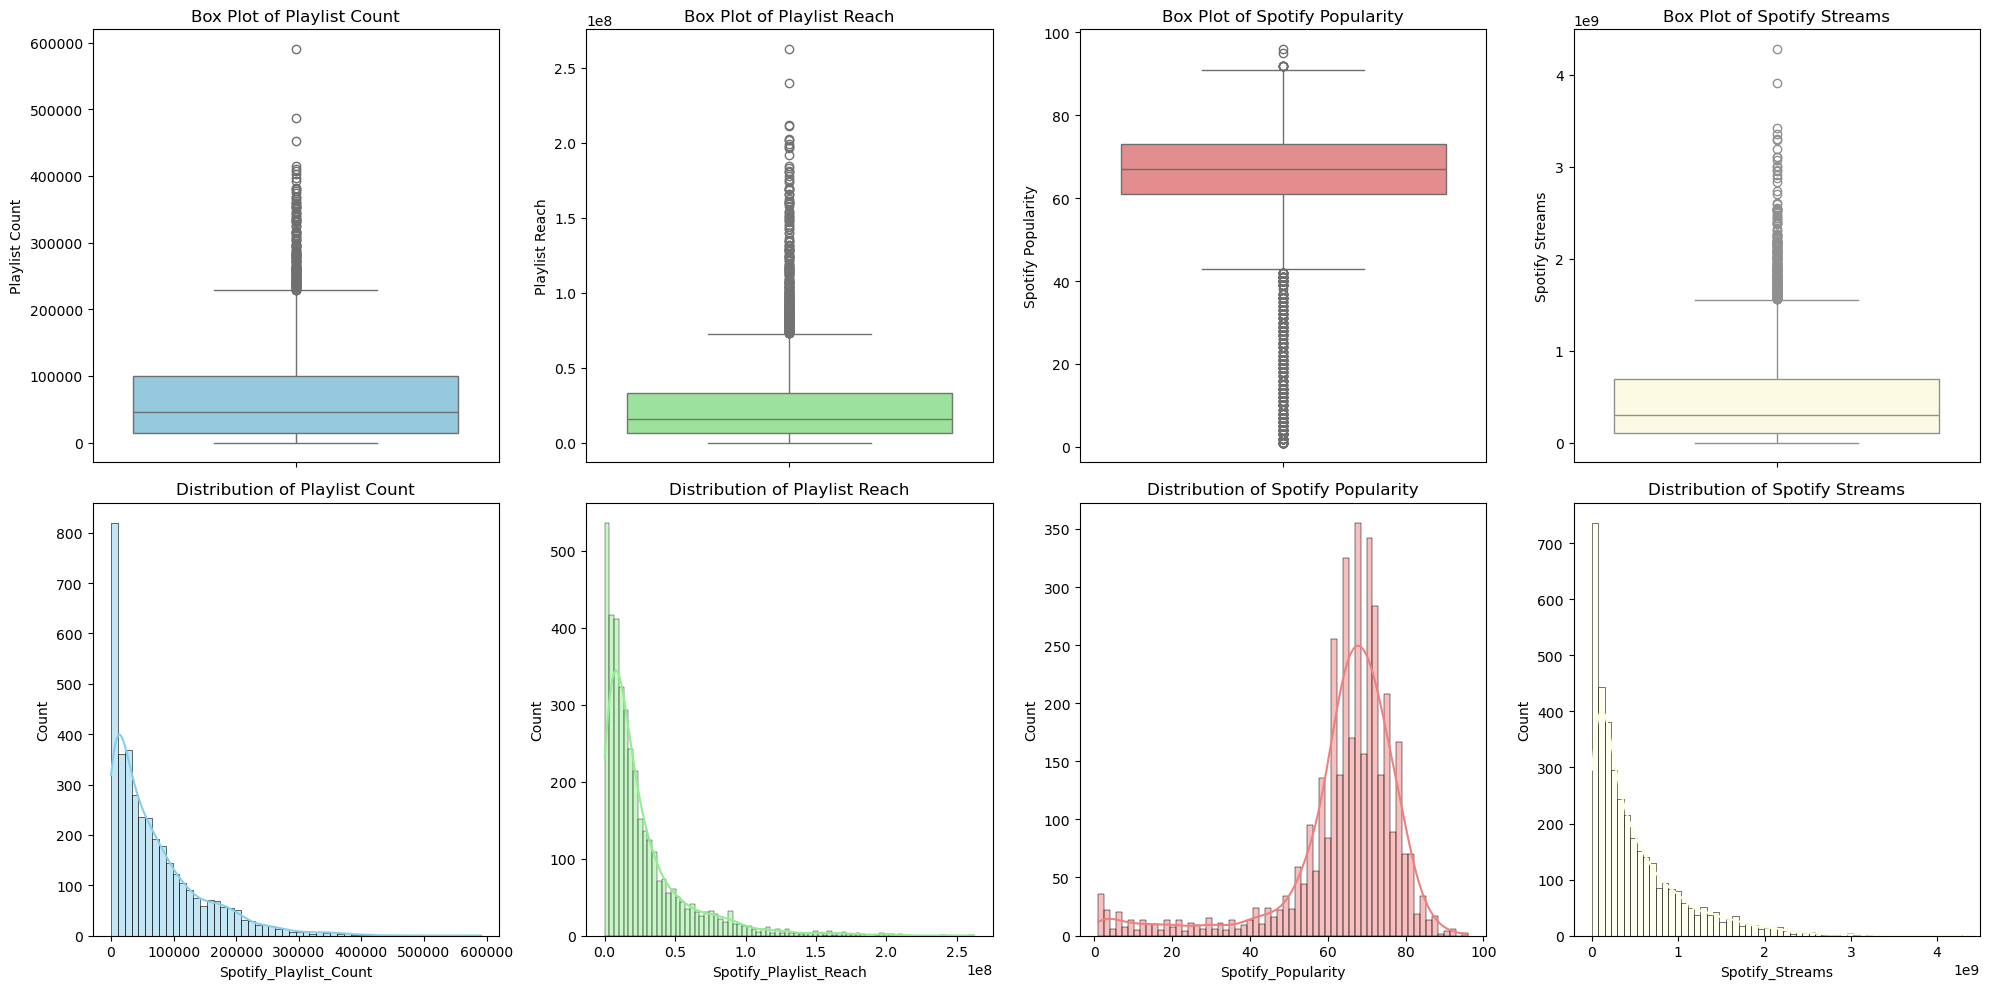

Percentage of artists with Playlist Count above 200,000: 6.75%
Percentage of artists with Playlist Reach above 100 million: 3.55%
Percentage of artists with Streams above 1 billion: 14.69%


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Create a figure and axis objects with 2 rows and 4 columns
fig, axes = plt.subplots(2, 4, figsize=(20, 10))

# Boxplot for Playlist Count
sns.boxplot(y=spotify_df['Spotify_Playlist_Count'], ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Box Plot of Playlist Count')
axes[0, 0].set_ylabel('Playlist Count')

# Boxplot for Playlist Reach
sns.boxplot(y=spotify_df['Spotify_Playlist_Reach'], ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title('Box Plot of Playlist Reach')
axes[0, 1].set_ylabel('Playlist Reach')

# Boxplot for Spotify Popularity
sns.boxplot(y=spotify_df['Spotify_Popularity'], ax=axes[0, 2], color='lightcoral')
axes[0, 2].set_title('Box Plot of Spotify Popularity')
axes[0, 2].set_ylabel('Spotify Popularity')

# Boxplot for Spotify Streams
sns.boxplot(y=spotify_df['Spotify_Streams'], ax=axes[0, 3], color='lightyellow')
axes[0, 3].set_title('Box Plot of Spotify Streams')
axes[0, 3].set_ylabel('Spotify Streams')

# Distribution plot for Playlist Count
sns.histplot(spotify_df['Spotify_Playlist_Count'], kde=True, ax=axes[1, 0], color='skyblue')
axes[1, 0].set_title('Distribution of Playlist Count')

# Distribution plot for Playlist Reach
sns.histplot(spotify_df['Spotify_Playlist_Reach'], kde=True, ax=axes[1, 1], color='lightgreen')
axes[1, 1].set_title('Distribution of Playlist Reach')

# Distribution plot for Spotify Popularity
sns.histplot(spotify_df['Spotify_Popularity'], kde=True, ax=axes[1, 2], color='lightcoral')
axes[1, 2].set_title('Distribution of Spotify Popularity')

# Distribution plot for Spotify Streams
sns.histplot(spotify_df['Spotify_Streams'], kde=True, ax=axes[1, 3], color='lightyellow')
axes[1, 3].set_title('Distribution of Spotify Streams')

# Adjust layout for better readability
plt.tight_layout()
plt.show()

# Calculate percentages of values above a certain threshold arbitrarily determined

# Define the thresholds
playlist_count_threshold = 200000
playlist_reach_threshold = 100000000  # 100 million
streams_threshold = 1000000000  # 1 billion

# Calculate the percentage of values above the threshold
percent_above_playlist_count = (spotify_df['Spotify_Playlist_Count'] > playlist_count_threshold).mean() * 100
percent_above_playlist_reach = (spotify_df['Spotify_Playlist_Reach'] > playlist_reach_threshold).mean() * 100
percent_above_streams = (spotify_df['Spotify_Streams'] > streams_threshold).mean() * 100

print(f"Percentage of artists with Playlist Count above 200,000: {percent_above_playlist_count:.2f}%")
print(f"Percentage of artists with Playlist Reach above 100 million: {percent_above_playlist_reach:.2f}%")
print(f"Percentage of artists with Streams above 1 billion: {percent_above_streams:.2f}%")


## Interpretation

The distribution analysis and visualizations provide key insights into the characteristics of the dataset and highlight the presence of skewness and outliers, which are essential considerations for further analysis.

#### Spotify Streams:

The distribution of Spotify Streams is heavily positively skewed, indicating that the majority of songs have relatively low streaming numbers. A small proportion of tracks have exceptionally high streams, which are outliers, visible in the box plot.
The majority of tracks fall well below 1 billion streams, with only 14.9% of tracks exceeding 1 billion streams. This suggests that the overall streaming landscape is dominated by a few extremely popular songs, while most songs receive considerably fewer streams.

#### Spotify Playlist Count:

Spotify Playlist Count also displays positive skewness, showing that the majority of tracks appear in a limited number of playlists. The distribution reveals that the count of playlists is concentrated towards the lower range, with only a few tracks having been added to a significantly large number of playlists.
The box plot shows the presence of many outliers, with only 6.75% of tracks appearing in more than 200,000 playlists, emphasizing the rarity of widespread playlist inclusion for most songs.

#### Spotify Playlist Reach:

Similarly, Spotify Playlist Reach is positively skewed, meaning that most songs have relatively limited exposure in terms of playlist reach. A few tracks have very high reach, as evident from the outliers in the box plot.
Only 3.55% of songs have a playlist reach exceeding 100 million, indicating that although playlists are a key mechanism for increasing visibility, only a small fraction of tracks benefit from significant playlist exposure.

#### Spotify Popularity:

In contrast, Spotify Popularity demonstrates a more symmetrical distribution but leans slightly toward negative skewness, with the majority of songs falling in the 60-80 popularity score range. This suggests that most songs in the dataset enjoy moderate popularity, with fewer songs achieving very low or very high popularity scores.
The outliers in the box plot indicate that there are some songs with particularly low or high popularity scores, but these are less frequent compared to other variables like streams or playlist count.


## 1.2 Relationships Between the Variables

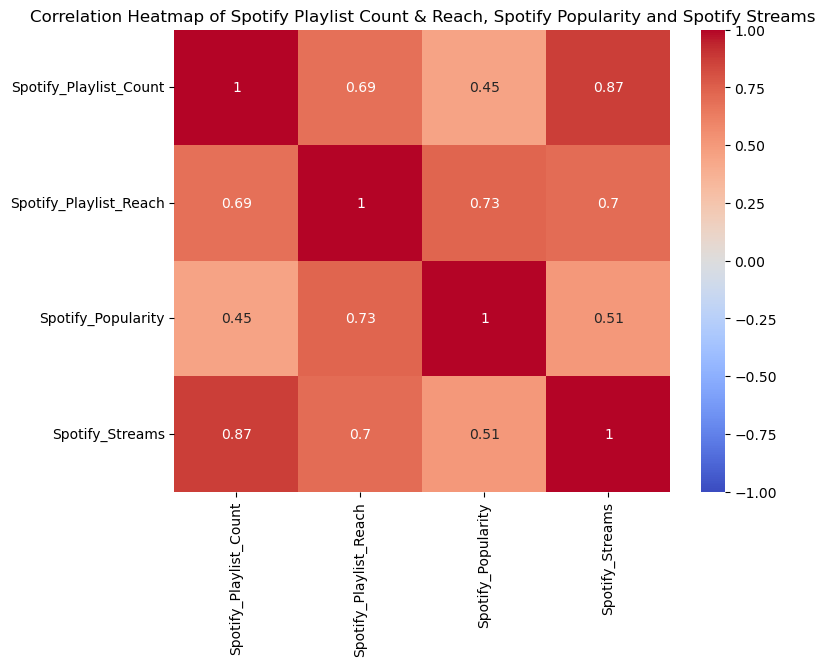

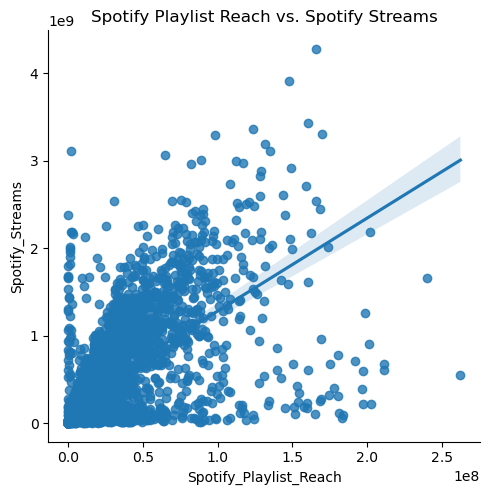

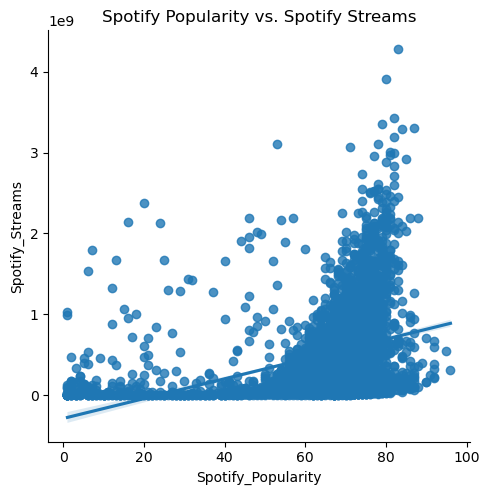

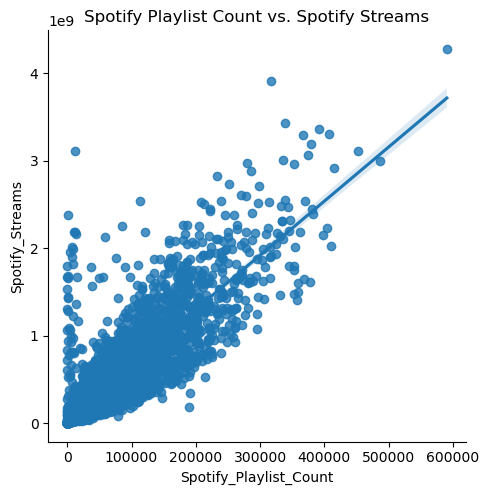

In [4]:
# Correlation (Spearman)
import seaborn as sns
import matplotlib.pyplot as plt

#Pearson correlation Matrix
correlation_matrix = spotify_df[['Spotify_Playlist_Count', 'Spotify_Playlist_Reach', 'Spotify_Popularity', 'Spotify_Streams']].corr(method= 'spearman')
#Create heatmap correlation matrix
plt.figure(figsize=(8,6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0)

plt.title('Correlation Heatmap of Spotify Playlist Count & Reach, Spotify Popularity and Spotify Streams')
plt.show()     

# Scatterplots with regressionline
sns.lmplot(x='Spotify_Playlist_Reach', y='Spotify_Streams', data=spotify_df)
plt.title('Spotify Playlist Reach vs. Spotify Streams')
plt.show()

sns.lmplot(x='Spotify_Popularity', y='Spotify_Streams', data=spotify_df)
plt.title('Spotify Popularity vs. Spotify Streams')
plt.show()

sns.lmplot(x='Spotify_Playlist_Count', y='Spotify_Streams', data=spotify_df)
plt.title('Spotify Playlist Count vs. Spotify Streams')
plt.show()


## Interpretation

#### Spotify Playlist Reach vs. Spotify Streams
##### Insight:
The Spearman correlation matrix reveals a strong positive correlation between Spotify Playlist Reach and Spotify Streams, with a coefficient of 0.7. This suggests that as the potential audience size for a song increases, its stream count tends to rise accordingly.

##### Observations:
The relationship is non-linear, with some degree of dispersion, particularly at higher values of playlist reach. This indicates that while reach generally correlates with an increase in streams, there is greater variability in stream counts as reach expands.

#### Spotify Playlist Count vs. Spotify Streams
##### Insight:
The correlation between Spotify Playlist Count and Spotify Streams is even stronger, with a coefficient of 0.87, indicating a robust positive linear relationship. This suggests that as the number of playlists a song is included in increases, the impact on streams is significant and consistent.

##### Observations:
The relationship between playlist count and streams is more linear than that of playlist reach, suggesting a more predictable and uniform effect on streams as playlist count rises. The data points are mostly clustered at lower playlist counts and streams, although a few outliers show much higher values. Overall, the strong correlation reflects a clear and consistent increase in streams as playlist count grows.

#### Spotify Popularity vs. Spotify Streams
##### Insight:
The correlation between Spotify Popularity and Spotify Streams is weaker and more complex, with a coefficient of 0.51. While there is a moderate positive relationship, it is not as strong as the playlist-related variables. Nevertheless, higher popularity values do tend to correspond with an increase in streams.

##### Observations:
At lower levels of popularity, there is little direct relationship between popularity and streams. However, at higher popularity values (around 60-80), the relationship becomes more apparent, though with increased variability. This indicates that while popularity does influence streams, other factors—such as playlist count and reach—seem to have a greater and more consistent effect on stream counts.

#### Correlations Between Independent Variables:
There is a notable correlation between the playlist-related metrics, with a strong relationship between Spotify Playlist Count and Spotify Playlist Reach. This indicates that as a song is included in more playlists, its potential reach expands accordingly, which is expected. The moderate correlation between Spotify Playlist Count and Spotify Popularity suggests that while songs in more playlists tend to have higher popularity scores, the relationship is not as strong as with reach. Finally, the strong correlation between Spotify Playlist Reach and Popularity indicates that songs reaching a larger audience tend to have higher popularity scores, reinforcing the connection between audience size and a track's overall popularity.

## 1.3 Distribution of Dependent Variables

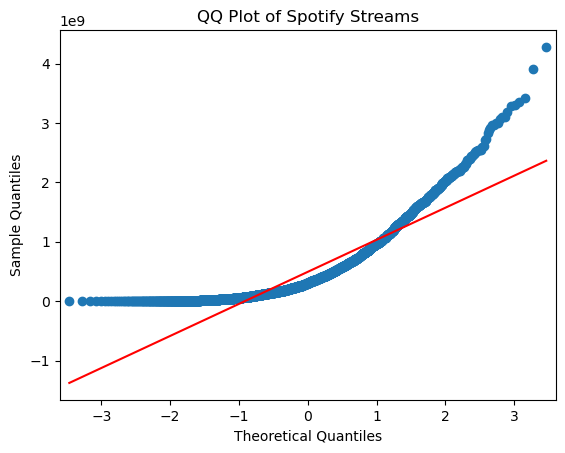

In [5]:
#QQ-Plot
import matplotlib.pyplot as plt
import statsmodels.api as sm
import numpy as np

# Create QQ plot for square root-transformed Spotify Streams
sm.qqplot(spotify_df['Spotify_Streams'], line='s')
plt.title('QQ Plot of Spotify Streams')
plt.show()

## Interpretation

The Q-Q plot shows that the dependent variable follows a normal distribution only in the central part, while moving towards the extremes, starting from quantiles 1 and -1, more values appear than would be expected in a normal distribution. This indicates that the tails are heavier than in a normal distribution, suggesting the presence of outliers or extreme values at both ends.
Knowing that a distribution deviating significantly from normality can negatively impact efficiency, we should aim to normalize our distribution as much as possible.
To do this we apply a root transformation, expressing the dependent variable Spotify Streams in squared units. 

## 2. The First Method

## 2.1 Multiple Linear Regression

The following Multiple Linear Regression (OLS) is going to test the influence of our independent variables Spotify Playlist Count, Spotify Playlist Reach and Spotify Popularity on our dependent variable Spotify Streams. Therefore our hypothesis looks as followed:

Null Hypothesis (H0):

The independent variables (Spotify Playlist Count, Spotify Playlist Reach and Spotify Popularity) have no effect on our dependent variable (Spotify Streams).

H0: $ß1 = ß2 = ß3 = 0$

Alternative Hypothesis (H1):

At least one of the idependent variables (Spotify Playlist Count, Spotify Playlist Reach and Spotify Popularity) has a statistically significant influence on the dependent variable (Spotify Streams). 

H1: $ß1 \neq 0$ or $ß2 \neq 0$ or $ß3 \neq 0$

The code in the next cell generates four OLS models for each dependent variable and afterwards there will be an interpretation of the results. 

In [6]:
import pandas as pd
import statsmodels.api as sm

# Dataset 
spotify_df = pd.DataFrame(spotify_df)

# Independent variables (Playlist Count, Playlist Reach, Popularity)
X = spotify_df[['Spotify_Playlist_Count', 'Spotify_Playlist_Reach', 'Spotify_Popularity']]

# Add a constant (for the intercept)
X = sm.add_constant(X)

# Dependent variables (Spotify Streams, YouTube Views, TikTok Views, Pandora Streams)
y_spotify = spotify_df['Spotify_Streams']
y_youtube = spotify_df['YouTube_Views']
y_tiktok = spotify_df['TikTok_Views']
y_pandora = spotify_df['Pandora_Streams']

# Regression for Spotify_Streams
model_spotify = sm.OLS(y_spotify, X).fit()
print("OLS for Spotify_Streams:")
print(model_spotify.summary())


OLS for Spotify_Streams:
                            OLS Regression Results                            
Dep. Variable:        Spotify_Streams   R-squared:                       0.729
Model:                            OLS   Adj. R-squared:                  0.729
Method:                 Least Squares   F-statistic:                     3385.
Date:                Fri, 04 Sep 2026   Prob (F-statistic):               0.00
Time:                        17:16:43   Log-Likelihood:                -78858.
No. Observations:                3778   AIC:                         1.577e+05
Df Residuals:                    3774   BIC:                         1.577e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
con

## Interpretation of the OLS

Starting with the interpretation of the OLS regression for the dependent variable Spotify Streams, the R-squared value of 0.729 indicates that 72.9% of the variance in Spotify Streams is explained by the independent variables. This suggests that the model accounts for a large proportion of the variability in Spotify Streams. Additionally, the F-statistic of 3385 reflects that the model is statistically significant, and the p-value for the F-statistic (Pr > F) being 0.00 confirms the high significance of the OLS model.

The intercept of the OLS model is also significant (p < 0.001) with a value of 59,730,000. This implies that if all independent variables were zero, the baseline for Spotify Streams would be 59,730,000. The β1-coefficient (Spotify Playlist Count) is statistically significant (p < 0.001) with a value of 5450.6, meaning that, all else equal (ceteris paribus, c.p.), adding a song to one more playlist is associated with an increase of approximately 5450.6 Spotify streams. The T-value of 69.636 provides strong evidence against the null hypothesis, confirming that the Spotify Playlist Count significantly influences Spotify Streams.

The β2-coefficient (Spotify Playlist Reach) is also statistically significant, with a p-value below 0.05 and a T-value of 16.046, indicating strong evidence against the null hypothesis. The β2-coefficient suggests that an increase of one in Spotify Playlist Reach leads to an increase of about 3.12 streams, assuming all other variables remain constant.

However, the β3-coefficient (Spotify Popularity) is not statistically significant, with a p-value of 0.178. Therefore, interpreting this coefficient is less meaningful. The coefficient implies that an increase in Spotify Popularity by one unit would result in a decrease of 447,500 streams, but since it lacks statistical significance, this relationship should be interpreted with caution.

The Durbin-Watson statistic of 1.956 indicates no autocorrelation in the residuals, meaning that the residuals are independent of each other. However, the values for Omnibus, Skew, and Kurtosis suggest that the residuals are not normally distributed. Specifically, the skewness value of 2.44 and the kurtosis value of 17.163 indicate the presence of outliers and deviations from normality in the residuals.

As a result, in the subsequent steps of the analysis, it will be necessary to assess and address the assumptions of multiple linear regression.

## 2.2 Assumptions

Under following assumptions the Gauss-Markov Theorem states that the OLS estimator is Best Linear Unbiased Estimator:

1. Linearity in parameters
2. No perfect multicollinearity
3. Exogeneity of independent variables
4. Homoscedasticity
5. Independence of errors

In the following part of the analysis we are going to proof if these assumptions are given for the OLS of chapter 2.1.

## 2.2.1 Linearity

Text(0.5, 1.0, 'Actual vs. Predicted')

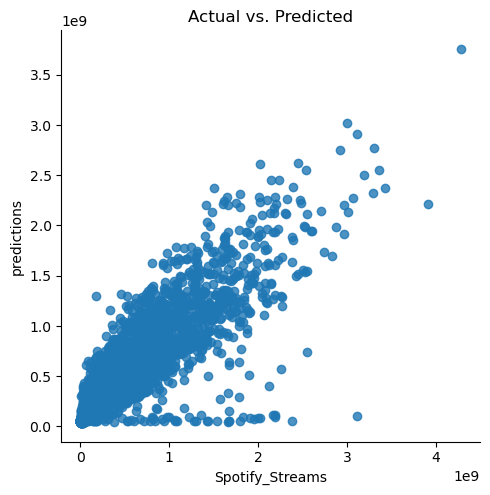

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

#Linearity Spotify
spotify_df['predictions'] = model_spotify.predict()
spotify_df['residuals'] = model_spotify.resid

# Plotting the actual vs predicted values
sns.lmplot(x='Spotify_Streams', y='predictions', data=spotify_df, fit_reg=False)        
plt.title('Actual vs. Predicted')


## Interpretation

The predicted and actual values of Spotify streams do not follow a straight line. In the lower range of Spotify streams, we can see a tighter clustering of values. However, as streaming numbers increase, the plot takes on a funnel shape, indicating more variability at higher values. The outliers on the right side of the graph may influence the regression line, potentially causing bias. As a result, the linearity assumption may not hold across the entire data range due to these outliers.

It's also noticeable that some points show high actual Spotify streams but have predictions close to zero, which mirrors the pattern seen in the scatter plot between Spotify Streams and Spotify Popularity. To improve the model, a potential solution could be to apply a transformation to the Spotify Streams data, which will be explored later in the analysis.

## 2.2.2 Multicollinearity

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = spotify_df[['Spotify_Playlist_Count', 'Spotify_Playlist_Reach', 'Spotify_Popularity']]
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
print(vif_data)

                  Feature  VIF
0  Spotify_Playlist_Count 3.00
1  Spotify_Playlist_Reach 2.80
2      Spotify_Popularity 2.47


## Interpretation

As all our VIFs for the dependent variables are below the conservative treshold of 5, multicollinearity is not a problem in our model.

## 2.2.3 Normality of Residuals

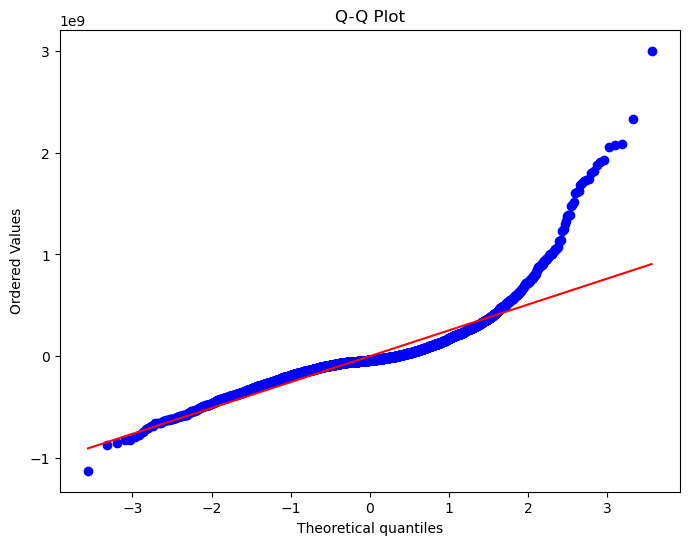

In [9]:
import scipy.stats as stats

# Q-Q plot for normality
plt.figure(figsize=(8,6))
stats.probplot(spotify_df['residuals'], dist="norm", plot=plt)
plt.title('Q-Q Plot')
plt.show()

## Interpretation

As we can see for larger observations our standard errors do not follow a normal distribution.

## 2.2.4 Homoscedasticity

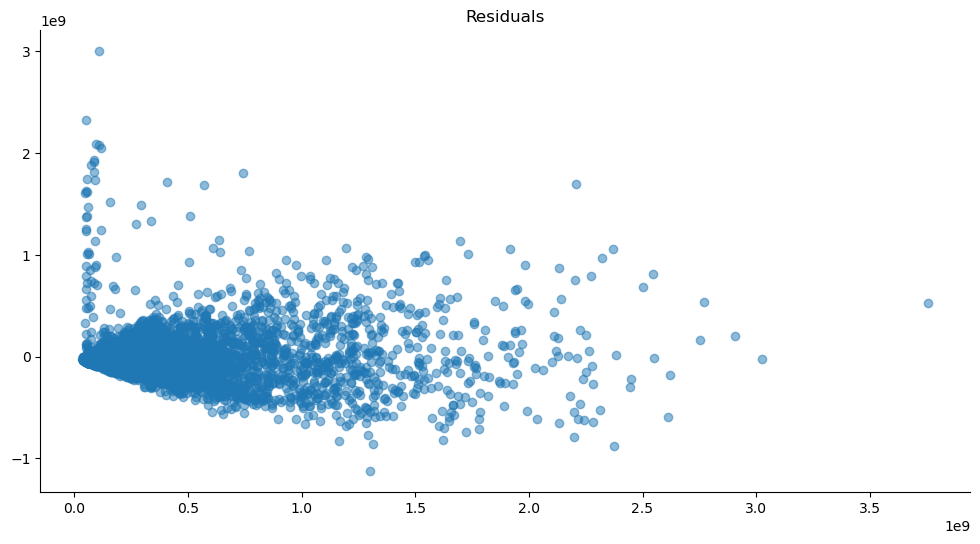

In [10]:
# Plotting the residuals
plt.subplots(figsize=(12, 6))
ax = plt.subplot(111)  # To remove spines
plt.scatter(x=spotify_df.predictions, y=spotify_df.residuals, alpha=0.5)
ax.spines['right'].set_visible(False)  # Removing the right spine
ax.spines['top'].set_visible(False)  # Removing the top spine
plt.title('Residuals')
plt.show()

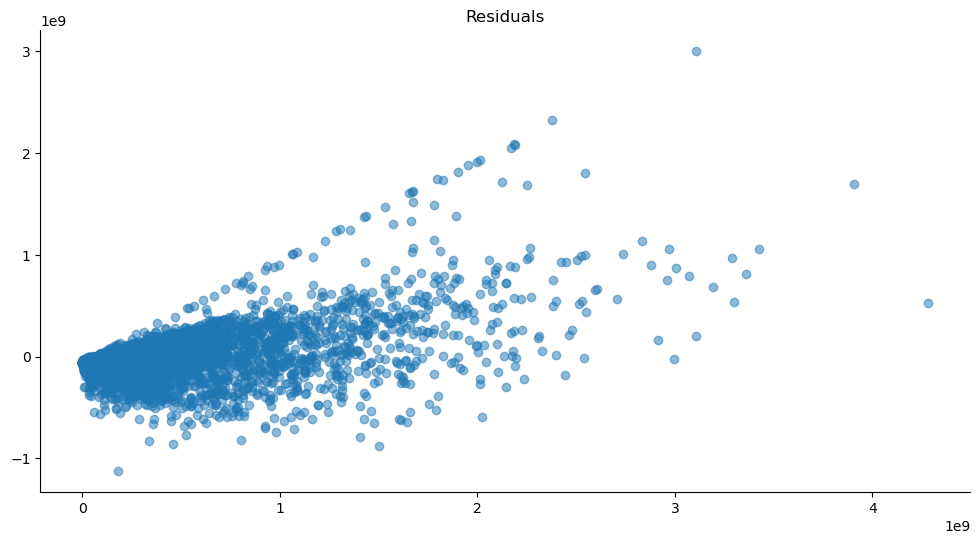

In [11]:
# Plotting the residuals
plt.subplots(figsize=(12, 6))
ax = plt.subplot(111)  # To remove spines
plt.scatter(x=spotify_df.Spotify_Streams, y=spotify_df.residuals, alpha=0.5)
ax.spines['right'].set_visible(False)  # Removing the right spine
ax.spines['top'].set_visible(False)  # Removing the top spine
plt.title('Residuals')
plt.show()

## Interpretation

As noted earlier, the residuals increase as the predicted and actual Spotify streams increase, which indicates the presence of heteroscedasticity. This suggests that outliers in the model could be disproportionately influencing the linear regression estimates. For songs with a high number of streams, the residuals tend to be positive, indicating that the model is underestimating the actual values.

Due to this unequal variance in the residuals, the standard errors may be underestimated, leading to potentially inaccurate p-values. To address this, transforming the dependent variable (Spotify Streams) could improve the model's accuracy.

## 2.2.5 Independence of Errors (autocorrelation of errors)

In [12]:
from statsmodels.stats.stattools import durbin_watson

# Perform the Durbin-Watson test
dw_test = durbin_watson(spotify_df['residuals'])
print(f'Durbin-Watson Test: {dw_test}')

Durbin-Watson Test: 1.9558531641484187


## Interpretation

As our Durbin-Watson Test value is between 1.5 and 2.5 the residuals seem to be independent.

## 2.2.6 Conclusion of the First Method

As we could see in the description before some of the assumptions for the best linear unbiased estimator are not valid for our model. The model harms the assumptions of Homoscedasticity and Linearity which indicates that the variables do not follow a normal distribution and can cause a biased effect. Therfore this analysis proceeds further by eliminating the outliers of the dependent variable through a square root transformation in order to have a more precise regression model.

## 2.3 Root Squared Tranformation

As we were facing lots of outliers on especially Spotify songs with high streaming numbers we decided to to a transformation of our data in a square root model. As the influence of the square root especially has a high influence on larger numbers and decreasing them stronger than smaller numbers.

## 2.3.1 QQ Plot

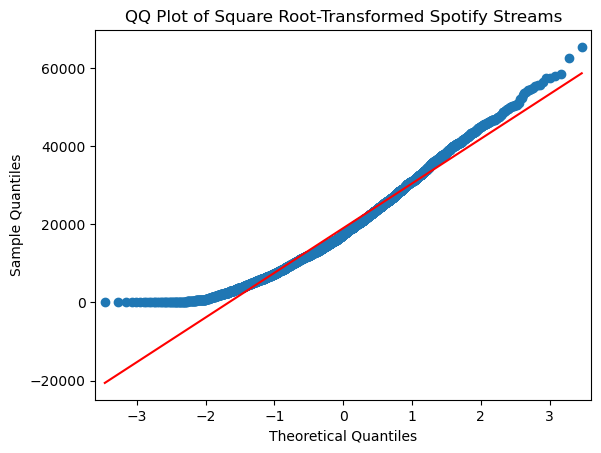

In [13]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
import numpy as np

# Apply square root transformation to Spotify Streams
spotify_df['sqrt_Spotify_Streams'] = np.sqrt(spotify_df['Spotify_Streams'])

# Create QQ plot for square root-transformed Spotify Streams
sm.qqplot(spotify_df['sqrt_Spotify_Streams'], line='s')
plt.title('QQ Plot of Square Root-Transformed Spotify Streams')
plt.show()

## Interpretation

As a result of applying the square root transformation, we observe a consistent improvement for higher values, which now align more closely with the theoretical quantiles. However, for lower values, which are less sensitive to the square root transformation, the improvement is less pronounced, and the points deviate more from the normality line.
Anyways, the transformation was able to improve our data towards a normal distribution.

## 2.3.2 Squared Root Multiple Linear Regression

In [14]:
import numpy as np
import statsmodels.api as sm

# Apply square root transformation to the dependent variable (Spotify Streams)
spotify_df['sqrt_Spotify_Streams'] = np.sqrt(spotify_df['Spotify_Streams'])

# Independent variables (Spotify Playlist Count, Playlist Reach, Popularity)
X = spotify_df[['Spotify_Playlist_Count', 'Spotify_Playlist_Reach', 'Spotify_Popularity']]

# Add a constant (for the intercept)
X = sm.add_constant(X)

# Dependent variable (Square Root of Spotify Streams)
y_sqrt_spotify = spotify_df['sqrt_Spotify_Streams']

# Fit the regression model
model_sqrt_spotify = sm.OLS(y_sqrt_spotify, X).fit()

# Print the summary of the regression
print(model_sqrt_spotify.summary())

                             OLS Regression Results                             
Dep. Variable:     sqrt_Spotify_Streams   R-squared:                       0.724
Model:                              OLS   Adj. R-squared:                  0.723
Method:                   Least Squares   F-statistic:                     3292.
Date:                  Fri, 04 Sep 2026   Prob (F-statistic):               0.00
Time:                          17:16:44   Log-Likelihood:                -38237.
No. Observations:                  3778   AIC:                         7.648e+04
Df Residuals:                      3774   BIC:                         7.651e+04
Df Model:                             3                                         
Covariance Type:              nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const   

## Interpretation of the Squared Root OLS

When comparing the OLS results from the square root transformation to those from the untransformed model in section 2.1, both similarities and differences emerge. Firstly, the R-squared value is similar to that of the other OLS model, indicating that both models explain a substantial portion of the variance in Spotify Streams. Furthermore, the F-statistic and the associated Prob(F-statistic) confirm that the model is statistically significant.

In terms of coefficients, a notable change is observed in the square root model, where all coefficients are statistically relevant. This suggests that all independent variables positively influence Spotify Streams, with their respective T-values providing strong evidence against the null hypothesis. In the square root regression, the coefficient for Spotify Popularity also shows a positive impact on Spotify Streams, making it more logically consistent compared to the untransformed model, as higher popularity should indeed correlate with increased streams.

Additionally, when comparing the skewness and kurtosis values of the square root OLS with those from the untransformed OLS, an improvement in the distribution of the residuals is evident. Specifically, there is a reduction in the number of outliers, as indicated by the kurtosis of the square root model (9.45), which is significantly lower than that of the untransformed OLS (17.163).


## 3. The Second Method Mann-Whitney U Test

## 3.1 Two Sampled Problem

In the following chapter, we aim to examine the differences in Spotify Streams based on the independent variables. Specifically, we will split each independent variable into two groups—high and low—and compare whether there is a significant difference in Spotify Streams between these groups. This analysis will help us determine if factors such as Spotify Popularity, Playlist Count, and Reach have a significant impact on streaming numbers.

To do this, we divide the data into two groups using the 25th percentile (the 0.25 quartile) as the cutoff. The lower group consists of the bottom 25% of values for each independent variable, while the higher group includes the remaining 75%.

Since the assumption of normal distribution is not met for our data set, we will use the Mann-Whitney U test, which does not require normally distributed data. The advantage of this test is that it is less affected by outliers, as it compares medians rather than means, making it more robust for our analysis.

## 3.2 Test on Spotify Playlist Count 

For the independent variable Spotify Playlist Count the hypothesis is described as followed:

Null Hypothesis (H0): 
The average number of streams of the group with a high value of Spotify Playlist Count equals the average numbers of streams for the group with a low value of Spotify Playlist Count.

Alternative Hypothesis(H1):
The average number of streams of the group with a high value of Spotify Playlist Count does not equal the average numbers of streams for the group with a low value of Spotify Playlist Count.

In [15]:
from scipy.stats import mannwhitneyu

# Calculate the 25th percentile for Spotify Playlist Count
percentile_25 = spotify_df['Spotify_Playlist_Count'].quantile(0.25)

# Create groups: High (above 25th percentile) and Low (below or equal to 25th percentile)
high_playlist_count = spotify_df[spotify_df['Spotify_Playlist_Count'] > percentile_25]['Spotify_Streams']
low_playlist_count = spotify_df[spotify_df['Spotify_Playlist_Count'] <= percentile_25]['Spotify_Streams']

median_high_playlist_count = spotify_df[spotify_df['Spotify_Playlist_Count'] > percentile_25]['Spotify_Streams'].median()
median_low_playlist_count = spotify_df[spotify_df['Spotify_Playlist_Count'] <= percentile_25]['Spotify_Streams'].median()

print(f"High Playlist Count Median: {median_high_playlist_count:.2f}")
print(f"Low Playlist Count Median: {median_low_playlist_count:.2f}")

# perform mann whitney test 
stat, p_value = mannwhitneyu(high_spotify_popularity, low_spotify_popularity)
print('Statistics=%.2f, p=%.2f' % (stat, p_value)) 
# Level of significance 
alpha = 0.05
# conclusion 
if p_value < alpha: 
    print('Reject Null Hypothesis (Significant difference between two samples)') 
else: 
    print('Do not Reject Null Hypothesis (No significant difference between two samples)')


High Playlist Count Median: 444613276.00
Low Playlist Count Median: 39057770.00


NameError: name 'high_spotify_popularity' is not defined

## 3.3 Test on Spotify Playlist Reach

For the independent variable Spotify Playlist Reach the hypothesis is described as followed:

Null Hypothesis (H0): 
The average number of streams of the group with a high value of Spotify Playlist Reach equals the average numbers of streams for the group with a low value of Spotify Playlist Reach.

Alternative Hypothesis(H1):
The average number of streams of the group with a high value of Spotify Playlist Reach does not equal the average numbers of streams for the group with a low value of Spotify Playlist Reach.

In [ ]:
from scipy.stats import mannwhitneyu

# Calculate the 25th percentile for Spotify Playlist Reach
percentile_25 = spotify_df['Spotify_Playlist_Reach'].quantile(0.25)

# Create groups: High (above 25th percentile) and Low (below or equal to 25th percentile)
high_playlist_reach = spotify_df[spotify_df['Spotify_Playlist_Reach'] > percentile_25]['Spotify_Streams']
low_playlist_reach = spotify_df[spotify_df['Spotify_Playlist_Reach'] <= percentile_25]['Spotify_Streams']

median_high_playlist_reach = spotify_df[spotify_df['Spotify_Playlist_Reach'] > percentile_25]['Spotify_Streams'].median()
median_low_playlist_reach = spotify_df[spotify_df['Spotify_Playlist_Reach'] <= percentile_25]['Spotify_Streams'].median()

print(f"High Playlist Reach Median: {median_high_playlist_reach:.2f}")
print(f"Low Playlist Reach Median: {median_low_playlist_reach:.2f}")

# perform mann whitney test 
stat, p_value = mannwhitneyu(high_playlist_reach, low_playlist_reach) 
print('Statistics=%.2f, p=%.2f' % (stat, p_value)) 
# Level of significance 
alpha = 0.05
# conclusion 
if p_value < alpha: 
    print('Reject Null Hypothesis (Significant difference between two samples)') 
else: 
    print('Do not Reject Null Hypothesis (No significant difference between two samples)')

## 3.4 Test on Spotify Popularity 

For the independent variable Spotify Popularity the hypothesis is described as followed:

Null Hypothesis (H0): 
The average number of streams of the group with a high value of Spotify Popularity equals the average numbers of streams for the group with a low value of Spotify Popularity.

Alternative Hypothesis(H1):
The average number of streams of the group with a high value of Spotify Popularity does not equal the average numbers of streams for the group with a low value of Spotify Popularity.

In [ ]:
from scipy.stats import mannwhitneyu

# Calculate the 25th percentile for Spotify Popularity
percentile_25 = spotify_df['Spotify_Popularity'].quantile(0.25)

# Create groups: High (above 25th percentile) and Low (below or equal to 25th percentile)
high_spotify_popularity = spotify_df[spotify_df['Spotify_Popularity'] > percentile_25]['Spotify_Streams']
low_spotify_popularity = spotify_df[spotify_df['Spotify_Popularity'] <= percentile_25]['Spotify_Streams']

median_high_spotify_popularity = spotify_df[spotify_df['Spotify_Popularity'] > percentile_25]['Spotify_Streams'].median()
median_low_spotify_popularity = spotify_df[spotify_df['Spotify_Popularity'] <= percentile_25]['Spotify_Streams'].median()

print(f"High Spotify Popularity Mean: {median_high_spotify_popularity:.2f}")
print(f"Low Spotify Popularity Mean: {median_low_spotify_popularity:.2f}")

# perform mann whitney test 
stat, p_value = mannwhitneyu(high_popularity, low_popularity) 
print('Statistics=%.2f, p=%.2f' % (stat, p_value)) 
# Level of significance 
alpha = 0.05
# conclusion 
if p_value < alpha: 
    print('Reject Null Hypothesis (Significant difference between two samples)') 
else: 
    print('Do not Reject Null Hypothesis (No significant difference between two samples)')

## Interpretation of the Second Method

In summary, the rejection of the null hypothesis for all three independent variables indicates that Spotify Playlist Count, Spotify Playlist Reach, and Spotify Popularity all have a significant impact on a track’s streaming performance. Songs that appear in more playlists, in playlists with greater reach, and that have higher popularity scores tend to perform significantly better in terms of Spotify streams. This highlights the importance of playlist placement and audience engagement in driving a track's success on the platform. These results align with industry realities where playlist strategies, audience targeting, and engagement are essential for driving music success on streaming platforms. Artists need to focus not only on getting their music into playlists but also on maximizing the reach and engagement to see significant gains in streams.

## 4. Conclusion

Our multiple linear regression model demonstrates a significant influence of at least two independent variables (Spotify Playlist Count and Spotify Playlist Reach) on the dependent variable, Spotify Streams. However, the analysis also reveals that for songs with high streaming numbers, the model tends to underestimate the actual outcomes. This discrepancy suggests the presence of outliers that may violate the model's assumptions and complicate the overall interpretation of our initial findings. Fortunately, by applying a square root transformation, we were able to mitigate the bias introduced by these outliers. Notably, this transformation also rendered the third variable, Spotify Popularity, a significant factor influencing Spotify Streams. In summary, all Spotify data metrics exhibit a positive and substantial impact on overall streaming performance.

The conclusions drawn earlier are further supported by the two-sampled Mann-Whitney U Test discussed in section 3. These tests indicate a significant difference in the number of Spotify Streams based on a song's Playlist Count, Playlist Reach, or Spotify Popularity. This reinforces the importance of these metrics, illustrating their strong influence on a song's streaming performance. The results not only affirm the positive relationship identified in the OLS models but also highlight that the impact varies significantly when a song has higher Playlist Counts, Playlist Reach, or Popularity.

The insights gained from this analysis have significant implications for artists and their management teams. Understanding that higher Playlist Counts and Reach correlate with increased streams can inform marketing strategies and decision-making. For instance, artists and their teams can prioritize efforts to get their music onto popular playlists, as this will likely enhance their visibility and listening numbers.

Additionally, the positive influence of Spotify Popularity on streaming performance emphasizes the need for artists to engage with their audience actively and build a strong brand presence. This can involve leveraging social media, collaborating with influencers, and maintaining consistent communication with fans to increase their popularity on the platform.

For management teams, these findings highlight the importance of data analytics in shaping business strategies. By continuously monitoring and analyzing streaming metrics, managers can make informed decisions about promotional efforts, tour planning, and resource allocation. Ultimately, a data-driven approach enables artists and their management to optimize their strategies, maximize streaming performance, and enhance their overall success in the competitive music industry.